# Completed v3 human-reviewed seed: precision and recall

**These are the completed 42-case reviewed BCL2 seed results, not the full curated
100-interaction test5 run.** This notebook is read-only with respect to earlier runs;
it recomputes the saved scores and writes its own table/figure beside this notebook.
There are 38 human-labeled positives and 4 negatives imported from the existing manual
review workbook. The set is small and enriched for earlier errors, not a held-out estimate
of corpus performance. No inference, NER or network requests are made here.

`02_analysis.ipynb` evaluates the full curated experiment after running `01`.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "src/dgilit/dgilit_models.py").exists())
sys.path.insert(0, str(REPO_ROOT / "src"))
from dgilit.evaluation import read_jsonl, summarize
from dgilit.pmc_store import digest

BENCHMARK_DIR = REPO_ROOT / "data/classification_benchmark"
OUTPUT_DIR = REPO_ROOT / "notebooks/test_sets/test5_dgidb_qwen_v3_prompt"
cases = read_jsonl(BENCHMARK_DIR / "reviewed.jsonl")
strict_dir = BENCHMARK_DIR / "seed_comparison"
inclusive_dir = BENCHMARK_DIR / "seed_comparison_inclusive"
strict_records = read_jsonl(strict_dir / "results.jsonl")
inclusive_records = read_jsonl(inclusive_dir / "results.jsonl")
metadata = json.loads((inclusive_dir / "metadata.json").read_text())
systems = json.loads((inclusive_dir / "system_prompts.json").read_text())
assert metadata["benchmark_sha256"] == hashlib.sha256((BENCHMARK_DIR / "reviewed.jsonl").read_bytes()).hexdigest()
for version in ("v2", "v3"):
    assert {r["prompt_hash"] for r in inclusive_records if r["version"] == version} == {digest(systems[version])}
strict_report = summarize(cases, strict_records)
inclusive_report = summarize(cases, inclusive_records)
print(f"Reviewed seed: {len(cases)} cases; {sum(c['expected_interaction'] for c in cases)} positives; {sum(not c['expected_interaction'] for c in cases)} negatives")
print(f"Model: {metadata['model_id']}; revision: {metadata['model_revision']}")
print("The inclusive comparison reuses the verified original v2 baseline.")


Matplotlib is building the font cache; this may take a moment.


Reviewed seed: 42 cases; 38 positives; 4 negatives
Model: mlx-community/Qwen3-14B-4bit; revision: a4d9b2df59d2c150bef02fcbe0d91046b7ca33a4
The inclusive comparison reuses the verified original v2 baseline.


## Validated precision, recall and F1

Precision uses validated outputs; invalid outputs remain separate. Recall uses all 38
gold positives, so invalid positive cases count as unrecovered. F1 combines those precision
and recall values. Type/directionality accuracy is unavailable: no reviewed canonical
mechanism labels exist in this seed. Allowed-label validity does not establish accuracy.


In [2]:
scores = {}
for name, report, version in [("v2 baseline", inclusive_report, "v2"),
                               ("Original strict v3", strict_report, "v3"),
                               ("Revised inclusive v3", inclusive_report, "v3")]:
    score = report[version]
    precision, recall = score["precision"], score["recall"]
    scores[name] = {"TP": score["counts"].get("tp", 0), "FP": score["counts"].get("fp", 0),
                   "TN": score["counts"].get("tn", 0), "FN (valid negatives)": score["counts"].get("fn", 0),
                   "Invalid": score["counts"].get("invalid", 0),
                   "Precision": precision, "Recall": recall,
                   "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0,
                   "Invalid rate": score["invalid_output_rate"]}
metrics = pd.DataFrame.from_dict(scores, orient="index")
metrics.to_csv(OUTPUT_DIR / "reviewed_seed_metrics.csv", index_label="run")
display(metrics.style.format({c: "{:.2%}" for c in ["Precision", "Recall", "F1", "Invalid rate"]},
                            precision=0))


,TP,FP,TN,FN (valid negatives),Invalid,Precision,Recall,F1,Invalid rate
v2 baseline,35,4,0,2,1,89.74%,92.11%,90.91%,2.38%
Original strict v3,21,2,2,14,3,91.30%,55.26%,68.85%,7.14%
Revised inclusive v3,33,4,0,2,3,89.19%,86.84%,88.00%,7.14%


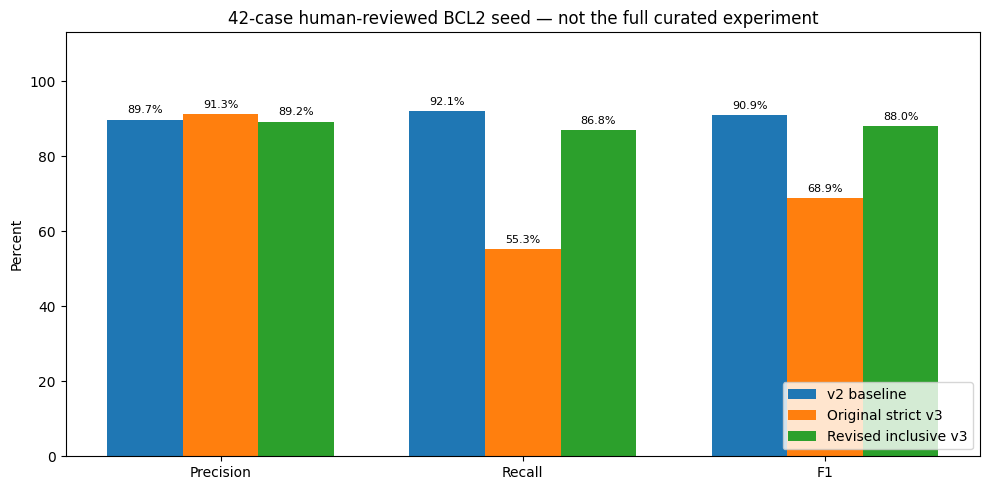

In [3]:
rates = ["Precision", "Recall", "F1"]
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(rates))
for offset, (name, row) in zip([-0.25, 0, 0.25], metrics.iterrows()):
    bars = ax.bar(x + offset, row[rates].to_numpy(dtype=float) * 100, width=0.25, label=name)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xticks(x, rates)
ax.set_ylim(0, 113)
ax.set_ylabel("Percent")
ax.set_title("42-case human-reviewed BCL2 seed — not the full curated experiment")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reviewed_seed_precision_recall.png", dpi=160)
plt.show()


## Decision agreement, quote failures and review cases

The revised v3 recovered 12 of the 14 positives newly missed by the original strict
prompt. Its raw interaction decisions match v2 on every case; its lower validated recall
comes from two additional rejected quotes. The four historical false positives remain.
The promotion gate fails and v2 remains the default.


In [4]:
by_version = {v: {r["id"]: r for r in inclusive_records if r["version"] == v} for v in ("v2", "v3")}
raw_agreement = sum(by_version["v2"][key]["raw_result"]["interaction"] == by_version["v3"][key]["raw_result"]["interaction"] for key in by_version["v2"])
recovered = [key for key in strict_report["newly_missed_positive_ids"]
             if by_version["v3"][key]["valid"] and by_version["v3"][key]["result"]["interaction"]]
print(f"Raw decision agreement with v2: {raw_agreement}/{len(cases)}")
print(f"Recovered previously missed positives: {len(recovered)}/{len(strict_report['newly_missed_positive_ids'])}")
print(f"Promotion gate passed: {inclusive_report['quantitative_gate_passed']}")
case_by_id = {c["id"]: c for c in cases}
failures = [{"pmid": case_by_id[r["id"]]["pmid"], "drug": case_by_id[r["id"]]["drug"],
             "gene": case_by_id[r["id"]]["gene"], "error": r["error"]}
            for r in inclusive_records if r["version"] == "v3" and not r["valid"]]
display(pd.DataFrame(failures))
review = pd.DataFrame(read_jsonl(inclusive_dir / "review_required.jsonl"))
display(review[["pmid", "drug", "gene", "previous_expected_interaction", "review_reasons"]])


Raw decision agreement with v2: 42/42
Recovered previously missed positives: 12/14
Promotion gate passed: False


,pmid,drug,gene,error
0,10914739,OBLIMERSEN,BCL2,Positive classification lacks a verifiable dir...
1,16741044,SB209670,BCL2,Positive classification lacks a verifiable dir...
2,8572591,TRETINOIN,BCL2,Positive classification lacks a verifiable dir...


,pmid,drug,gene,previous_expected_interaction,review_reasons
0,11906253,PROTAMINE,BCL2,False,[false positive against historical label]
1,10220568,BENZENE,BCL2,False,[false positive against historical label]
2,10914739,OBLIMERSEN,BCL2,True,"[newly missed positive versus v2, invalid v3 e..."
3,8324744,QUINAZOLINE,BCL2,False,[false positive against historical label]
4,16741044,SB209670,BCL2,True,[invalid v3 evidence quote]
5,8572591,TRETINOIN,BCL2,True,"[newly missed positive versus v2, invalid v3 e..."
6,16109552,TRETINOIN,BCL2,False,[false positive against historical label]
